<a href="https://colab.research.google.com/github/RiyaSunil28/nitinternship/blob/main/Week2_nit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install timm -q

In [ ]:
import torch
import timm
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

import pandas as pd

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [ ]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 170M/170M [03:09<00:00, 901kB/s]


In [ ]:
known_classes = [0, 1, 3, 5, 7]

unknown_classes = [2, 4, 6, 8, 9]

print("Known:", known_classes)
print("Unknown:", unknown_classes)

Known: [0, 1, 3, 5, 7]
Unknown: [2, 4, 6, 8, 9]


In [ ]:
known_test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in known_classes
]

unknown_test_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in unknown_classes
]

known_test = Subset(
    test_dataset,
    known_test_indices
)

unknown_test = Subset(
    test_dataset,
    unknown_test_indices
)

print("Known test samples:", len(known_test))
print("Unknown test samples:", len(unknown_test))

Known test samples: 5000
Unknown test samples: 5000


In [ ]:
known_loader = DataLoader(
    known_test,
    batch_size=64,
    shuffle=False
)

unknown_loader = DataLoader(
    unknown_test,
    batch_size=64,
    shuffle=False
)

In [ ]:
model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True
)

model.eval()
model.to(device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [ ]:
images, labels = next(iter(known_loader))

images = images.to(device)

with torch.no_grad():
    features = model.forward_features(images)

print(features.shape)

torch.Size([64, 197, 768])


In [ ]:
cls_features = features[:, 0]

print(cls_features.shape)

torch.Size([64, 768])


In [ ]:
def get_scores(loader):

    msp_scores = []
    energy_scores = []

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(device)

            logits = model(images)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            msp = probabilities.max(
                dim=1
            ).values

            energy = torch.logsumexp(
                logits,
                dim=1
            )

            msp_scores.extend(
                msp.cpu().numpy()
            )

            energy_scores.extend(
                energy.cpu().numpy()
            )

    return (
        np.array(msp_scores),
        np.array(energy_scores)
    )

In [ ]:
known_msp, known_energy = get_scores(
    known_loader
)

unknown_msp, unknown_energy = get_scores(
    unknown_loader
)

In [ ]:
labels = np.concatenate([

    np.ones(len(known_msp)),

    np.zeros(len(unknown_msp))

])

In [ ]:
msp_scores = np.concatenate([
    known_msp,
    unknown_msp
])

energy_scores = np.concatenate([
    known_energy,
    unknown_energy
])

msp_auroc = roc_auc_score(
    labels,
    msp_scores
)

energy_auroc = roc_auc_score(
    labels,
    energy_scores
)

print("MSP AUROC:", round(msp_auroc, 4))
print("Energy AUROC:", round(energy_auroc, 4))

MSP AUROC: 0.4172
Energy AUROC: 0.3922


In [ ]:
msp_threshold = np.percentile(
    known_msp,
    5
)

energy_threshold = np.percentile(
    known_energy,
    5
)

print("MSP threshold:", msp_threshold)
print("Energy threshold:", energy_threshold)

MSP threshold: 0.0977622
Energy threshold: 7.768221


In [ ]:
msp_fpr, msp_tpr, _ = roc_curve(
    labels,
    msp_scores
)

energy_fpr, energy_tpr, _ = roc_curve(
    labels,
    energy_scores
)

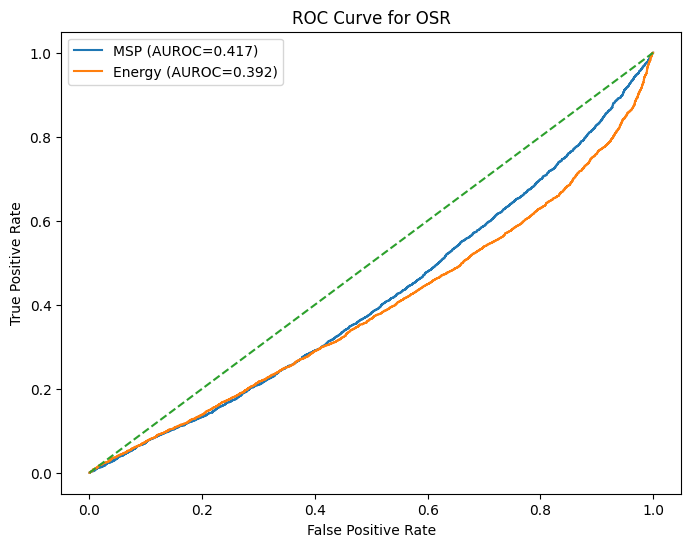

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    msp_fpr,
    msp_tpr,
    label=f"MSP (AUROC={msp_auroc:.3f})"
)

plt.plot(
    energy_fpr,
    energy_tpr,
    label=f"Energy (AUROC={energy_auroc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve for OSR")

plt.legend()

plt.show()

In [ ]:
results = pd.DataFrame({

    "Method": [
        "MSP",
        "Energy Score"
    ],

    "AUROC": [
        round(msp_auroc, 4),
        round(energy_auroc, 4)
    ]
})

results

,Method,AUROC
0,MSP,0.4172
1,Energy Score,0.3922
